$$ \Large{x_{start} = -0.915} $$

In [7]:
!git init

hint: Using 'master' as the name for the initial branch. This default branch name
hint: is subject to change. To configure the initial branch name to use in all
hint: of your new repositories, which will suppress this warning, call:
hint: 
hint: 	git config --global init.defaultBranch <name>
hint: 
hint: Names commonly chosen instead of 'master' are 'main', 'trunk' and
hint: 'development'. The just-created branch can be renamed via this command:
hint: 
hint: 	git branch -m <name>
Initialized empty Git repository in /home/d2contreras/private/Phys 142/.git/


In [11]:
!git branch -m Main

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy

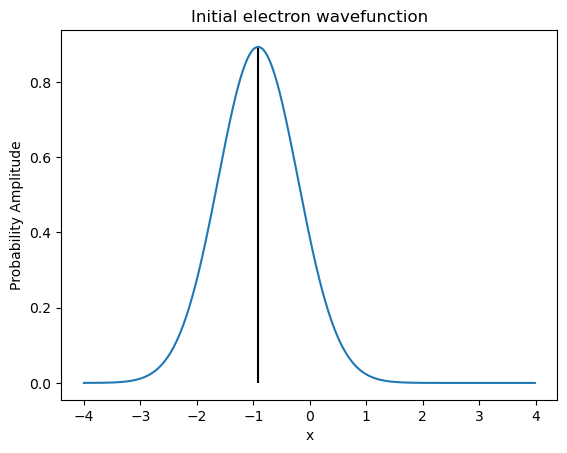

In [2]:
 #Miscellaneous parameters
m = 1
omega = 1
hbar = 1
period = 2*np.pi
dt = period/128
ND = 600
x0 = -4
xN = 4
alpha = 2
i = 1j


 #Create vector of starting positions
X_0 = np.zeros(ND)
for n in range(ND):
    X_0[n] = (x0 + ((xN-x0) / ND) * n)
    


TSN = 200224383
d = 83
s = 3
x_start = (-1)**s * (0.5 + d/200)


 #Initial wavefunction
def initial_psi(x):
    return (alpha/np.pi)**(1/4) * np.exp(-alpha/2 * (x - x_start)**2)


test = initial_psi(X_0)
plt.plot(X_0, test)
plt.xlabel('x')
plt.ylabel('Probability Amplitude')
plt.title('Initial electron wavefunction')
plt.vlines(x=x_start, ymin=0, ymax=0.89, color='black')

plt.show()

$$\large
K(x_N, t_N; \, x_0, t_0) = \int ... \, \int \, \int \, K(x_N, t_N; \, x_{N-1}, t_{N-1}) \, ... \, K(x_2, t_2; \, x_1, t_1) \, K(x_1, t_1; \, x_0, t_0) \, dx_1 \, dx_2 \, ... \, dx_{N-1}
$$

$$\large
K(x_b, T; \, x_a, 0) = (\frac{m\omega}{2\pi i \hbar \sin(\omega(T))})^{1/2} \quad \exp{(\frac{im\omega}{2\hbar\sin(\omega(T))}[(x_a^2 + x_b^2) \cos(\omega(T)) - 2x_ax_b])}
$$

$$\large
K_{x_i}(x_i, \, \Delta t; \, x_i, \, 0) = 
$$


In [20]:
 #Define objective function
#def propagator(xa, xb, delta_t):
#        return (m*omega/(2*np.pi*i))**(1/2) * np.exp(((i*m*omega)/(2*hbar*np.sin(omega*(delta_t)))) * ((xa**2 + xb**2) * np.cos(omega*(delta_t)) - 2*xa*xb))

def propagator(X, delta_t):
    X = np.real(X)
    V = np.zeros(ND)
    for a in range(ND):
        V[a] = (m*omega/(2*np.pi*i*hbar*np.sin(omega*delta_t)))**(1/2) * np.exp(((i*m*omega)/(2*hbar*np.sin(omega*(delta_t)))) * ((2*X[a]**2) * np.cos(omega*(delta_t)) - 2*X[a]**2))
    return V

In [22]:
 #Define grid
T = 8*dt
tsteps = np.linspace(0, T, 128)
X0,t = np.meshgrid(X_0, tsteps)
#print(X0)
 #Create propagator matrix
sol = np.array(propagator(X0[0], T), dtype=np.complex64)

/tmp/ipykernel_410/2372909163.py:9: ComplexWarning: Casting complex values to real discards the imaginary part
  V[a] = (m*omega/(2*np.pi*i*hbar*np.sin(omega*delta_t)))**(1/2) * np.exp(((i*m*omega)/(2*hbar*np.sin(omega*(delta_t)))) * ((2*X[a]**2) * np.cos(omega*(delta_t)) - 2*X[a]**2))


In [ ]:
x1,t1,x2,t2 = 0,0,1,1
check = propagator(x1,t1,x2,t2)
check